<a href="https://colab.research.google.com/github/rajalakshmie-png/confidentiality-gate/blob/main/LAF_MCDM_pipeline_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LAF-MCDM: fuzzy AHP–TOPSIS pipeline for cyber-risk prioritization
Human-in-the-loop, LLM-compatible proof-of-concept. Every "LLM" role is a deterministic rule.

## Setup: write the pipeline module and case-study data
Self-contained for Google Colab: just use **Runtime → Run all**.

In [1]:
%%writefile lafmcdm.py
"""LAF-MCDM: human-in-the-loop, LLM-compatible fuzzy AHP-TOPSIS pipeline.

Reconstructed from the method description in Rajalakshmi & Renuka Devi,
"LAF-MCDM: A Computational Proof-of-Concept ..." (Sections III-IV).
All "LLM" roles are deterministic rules with the same input/output contract.
"""
import numpy as np

CRITERIA = ["C1 Likelihood", "C2 Impact", "C3 Detectability",
            "C4 Remediation cost", "C5 Regulatory"]
CRIT_TYPE = ["benefit", "benefit", "cost", "benefit", "benefit"]
ALTS = ["R1 Ransomware", "R2 Insider threat", "R3 Phishing",
        "R4 Cloud misconfig.", "R5 Supply-chain", "R6 DDoS"]
EXPERTS = ["CISO", "SOC analyst", "Compliance officer",
           "IT infra lead", "Ext. consultant"]
RI = {3: 0.58, 4: 0.90, 5: 1.12, 6: 1.24, 7: 1.32}

# ---------- Triangular fuzzy numbers ----------
def tfn(c):
    """Fuzzify a crisp Saaty judgment c (Table II, extended to 2,4,6,8)."""
    if c >= 1:
        c = int(round(c))
        if c in (1, 9):
            return np.array([c, c, c], float)
        return np.array([c - 1, c, c + 1], float)
    l, m, u = tfn(1.0 / c)
    return np.array([1 / u, 1 / m, 1 / l])          # TFN reciprocal, Eq. (3)

def defuzz(a):
    return np.asarray(a, float).sum(axis=-1) / 3.0     # centroid

# ---------- Module 1: semantic elicitation (keyword rule, Table III) ----------
KEYWORDS = [  # checked strongest-first so "very clearly" wins over "clearly"
    (9, ["overwhelmingly", "by far the most", "dominates"]),
    (7, ["very clearly", "much more", "far more"]),
    (5, ["clearly", "noticeably", "more important"]),
    (3, ["slightly", "somewhat", "a bit more"]),
    (1, ["equal", "similar", "no difference"]),
]
LABEL = {1: "Equal", 3: "Moderate", 5: "Strong", 7: "Very strong", 9: "Extreme"}

def elicit(rationale):
    """Return (Saaty value, class label, TFN) as a CANDIDATE for expert confirmation."""
    text = rationale.lower()
    for value, cues in KEYWORDS:
        if any(cue in text for cue in cues):
            return value, LABEL[value], tfn(value)
    return 3, LABEL[3], tfn(3)                        # default: Moderate

# ---------- Module 2: consistency refinement ----------
def consistency_ratio(A):
    n = A.shape[0]
    lam = np.max(np.real(np.linalg.eigvals(A)))
    return ((lam - n) / (n - 1)) / RI[n]

def refine(A, threshold=0.10, max_iter=3):
    """Median-transitivity repair: replace the single entry whose substitution
    most reduces CR, keep reciprocity, repeat up to max_iter times."""
    A = A.astype(float).copy()
    n = A.shape[0]
    log = []
    for it in range(1, max_iter + 1):
        cr = consistency_ratio(A)
        if cr <= threshold:
            break
        best = None
        for i in range(n):
            for j in range(i + 1, n):
                implied = np.median([A[i, k] * A[k, j] for k in range(n) if k not in (i, j)])
                implied = float(np.clip(implied, 1 / 9, 9))
                trial = A.copy()
                trial[i, j], trial[j, i] = implied, 1 / implied
                new_cr = consistency_ratio(trial)
                if best is None or new_cr < best[0]:
                    best = (new_cr, i, j, A[i, j], implied)
        new_cr, i, j, old, new = best
        A[i, j], A[j, i] = new, 1 / new
        log.append(dict(iteration=it, entry=(i + 1, j + 1), old=old, new=new,
                        cr_before=cr, cr_after=new_cr))
    return A, log

# ---------- Fuzzy AHP weights (Buckley geometric mean) ----------
def fuzzy_matrix(A):
    return np.array([[tfn(A[i, j]) for j in range(len(A))] for i in range(len(A))])

def buckley_weights(A):
    F = fuzzy_matrix(A)                               # n x n x 3
    r = np.prod(F, axis=1) ** (1 / len(A))            # fuzzy geometric mean per row
    total = r.sum(axis=0)
    w = np.stack([r[:, 0] / total[2], r[:, 1] / total[1], r[:, 2] / total[0]], 1)
    crisp = defuzz(w)
    return crisp / crisp.sum(), w

# ---------- Module 3: group aggregation ----------
def geomean_aggregate(W):
    """W: experts x criteria crisp weights. Unweighted geometric mean, Eq. (4)."""
    g = np.prod(W, axis=0) ** (1 / W.shape[0])
    return g / g.sum()

def role_aggregate(W, C):
    """C: criteria x experts row-stochastic credibility matrix, Eq. (5)."""
    w = np.einsum("ik,ki->i", C, W)
    w = np.clip(w, W.min(axis=0), W.max(axis=0))      # expert envelope
    return w / w.sum()

# ---------- Fuzzy TOPSIS (Chen 2000) ----------
SCALE = {"VL": (0, 0, 2.5), "L": (0, 2.5, 5), "M": (2.5, 5, 7.5),
         "H": (5, 7.5, 10), "VH": (7.5, 10, 10)}

# Cost-criterion reference value. Calibrated so this reconstruction reproduces
# the paper's Table XII; the original code's exact constant is not published.
COST_LSTAR = 0.25

def fuzzy_topsis(ratings, weights, types=CRIT_TYPE):
    X = np.array([[SCALE[r] for r in row] for row in ratings], float)  # m x n x 3
    R = np.empty_like(X)
    for j, t in enumerate(types):
        if t == "benefit":
            R[:, j] = X[:, j] / X[:, j, 2].max()
        else:  # cost (Chen): r = l*/(u, m, l); zero bounds capped at 1
            with np.errstate(divide="ignore"):
                R[:, j] = np.minimum(COST_LSTAR / X[:, j, ::-1], 1.0)
    V = R * np.asarray(weights)[None, :, None]
    pos = np.repeat(np.asarray(weights)[:, None], 3, 1)
    d = lambda a, b: np.sqrt(((a - b) ** 2).mean(-1))  # vertex distance, Eq. (6)
    d_pos = d(V, pos[None]).sum(1)
    d_neg = d(V, 0).sum(1)
    cc = d_neg / (d_pos + d_neg)
    return d_pos, d_neg, cc

# ---------- Monte Carlo robustness ----------
def monte_carlo(ratings, weights, runs=10_000, alpha=40, seed=42):
    rng = np.random.default_rng(seed)
    draws = rng.dirichlet(alpha * np.asarray(weights), size=runs)
    top = np.empty(runs, int)
    ccs = np.empty((runs, len(ratings)))
    for r, w in enumerate(draws):
        _, _, cc = fuzzy_topsis(ratings, w)
        ccs[r] = cc
        top[r] = cc.argmax()
    return top, ccs


Writing lafmcdm.py


In [2]:
import os, json
os.makedirs('data', exist_ok=True); os.makedirs('figures', exist_ok=True)
DATA = {
"expert_matrices.json": "{\n \"note\": \"Demo pairwise matrices reconstructed from the paper's Table IX weights; one deliberate inconsistency injected in two profiles.\",\n \"matrices\": {\n  \"CISO\": [\n   [\n    1.0,\n    0.5,\n    4.0,\n    3.0,\n    2.0\n   ],\n   [\n    2.0,\n    1.0,\n    6.0,\n    5.0,\n    3.0\n   ],\n   [\n    0.25,\n    0.166667,\n    1.0,\n    1.0,\n    0.5\n   ],\n   [\n    0.333333,\n    0.2,\n    1.0,\n    1.0,\n    0.5\n   ],\n   [\n    0.5,\n    0.333333,\n    2.0,\n    2.0,\n    1.0\n   ]\n  ],\n  \"SOC analyst\": [\n   [\n    1.0,\n    0.5,\n    0.5,\n    3.0,\n    3.0\n   ],\n   [\n    2.0,\n    1.0,\n    1.0,\n    5.0,\n    4.0\n   ],\n   [\n    2.0,\n    1.0,\n    1.0,\n    6.0,\n    6.0\n   ],\n   [\n    0.333333,\n    0.2,\n    0.166667,\n    1.0,\n    1.0\n   ],\n   [\n    0.333333,\n    0.25,\n    0.166667,\n    1.0,\n    1.0\n   ]\n  ],\n  \"Compliance officer\": [\n   [\n    1.0,\n    0.5,\n    0.25,\n    2.0,\n    0.25\n   ],\n   [\n    2.0,\n    1.0,\n    3.0,\n    4.0,\n    0.5\n   ],\n   [\n    4.0,\n    0.333333,\n    1.0,\n    1.0,\n    0.142857\n   ],\n   [\n    0.5,\n    0.25,\n    1.0,\n    1.0,\n    0.111111\n   ],\n   [\n    4.0,\n    2.0,\n    7.0,\n    9.0,\n    1.0\n   ]\n  ],\n  \"IT infra lead\": [\n   [\n    1.0,\n    0.5,\n    9.0,\n    0.25,\n    3.0\n   ],\n   [\n    2.0,\n    1.0,\n    2.0,\n    0.5,\n    5.0\n   ],\n   [\n    0.111111,\n    0.5,\n    1.0,\n    0.2,\n    2.0\n   ],\n   [\n    4.0,\n    2.0,\n    5.0,\n    1.0,\n    9.0\n   ],\n   [\n    0.333333,\n    0.2,\n    0.5,\n    0.111111,\n    1.0\n   ]\n  ],\n  \"Ext. consultant\": [\n   [\n    1.0,\n    0.5,\n    2.0,\n    1.0,\n    1.0\n   ],\n   [\n    2.0,\n    1.0,\n    3.0,\n    3.0,\n    2.0\n   ],\n   [\n    0.5,\n    0.333333,\n    1.0,\n    1.0,\n    0.5\n   ],\n   [\n    1.0,\n    0.333333,\n    1.0,\n    1.0,\n    1.0\n   ],\n   [\n    1.0,\n    0.5,\n    2.0,\n    1.0,\n    1.0\n   ]\n  ]\n }\n}",
"expert_weights_table9.json": "{\n \"note\": \"Table IX of the paper: post-refinement per-expert weights\",\n \"weights\": {\n  \"CISO\": [\n   0.264,\n   0.416,\n   0.068,\n   0.089,\n   0.164\n  ],\n  \"SOC analyst\": [\n   0.183,\n   0.297,\n   0.39,\n   0.062,\n   0.069\n  ],\n  \"Compliance officer\": [\n   0.119,\n   0.248,\n   0.073,\n   0.056,\n   0.504\n  ],\n  \"IT infra lead\": [\n   0.142,\n   0.22,\n   0.096,\n   0.495,\n   0.046\n  ],\n  \"Ext. consultant\": [\n   0.207,\n   0.361,\n   0.108,\n   0.147,\n   0.177\n  ]\n }\n}",
"credibility_matrix.json": "{\n \"criteria_x_experts\": [\n  [\n   0.28,\n   0.24,\n   0.14,\n   0.14,\n   0.2\n  ],\n  [\n   0.3,\n   0.18,\n   0.18,\n   0.14,\n   0.2\n  ],\n  [\n   0.14,\n   0.4,\n   0.1,\n   0.16,\n   0.2\n  ],\n  [\n   0.14,\n   0.12,\n   0.14,\n   0.4,\n   0.2\n  ],\n  [\n   0.14,\n   0.1,\n   0.42,\n   0.14,\n   0.2\n  ]\n ]\n}",
"ratings_table7.json": "{\n \"ratings\": [\n  [\n   \"VH\",\n   \"VH\",\n   \"M\",\n   \"VH\",\n   \"H\"\n  ],\n  [\n   \"M\",\n   \"H\",\n   \"L\",\n   \"M\",\n   \"H\"\n  ],\n  [\n   \"VH\",\n   \"M\",\n   \"M\",\n   \"L\",\n   \"M\"\n  ],\n  [\n   \"M\",\n   \"H\",\n   \"L\",\n   \"M\",\n   \"VH\"\n  ],\n  [\n   \"L\",\n   \"VH\",\n   \"VL\",\n   \"VH\",\n   \"H\"\n  ],\n  [\n   \"H\",\n   \"M\",\n   \"H\",\n   \"L\",\n   \"L\"\n  ]\n ]\n}"
}
for name, text in DATA.items():
    open(f'data/{name}', 'w').write(text)
print('Wrote', sorted(DATA))

Wrote ['credibility_matrix.json', 'expert_matrices.json', 'expert_weights_table9.json', 'ratings_table7.json']


In [3]:
# Colab runtime specification (for the Environment slide)
!nproc
!free -h
!lscpu | grep 'Model name'
!df -h / | tail -1
!nvidia-smi -L 2>/dev/null || echo 'No GPU'

2
               total        used        free      shared  buff/cache   available
Mem:            12Gi       982Mi       9.3Gi       2.2Mi       2.7Gi        11Gi
Swap:             0B          0B          0B
Model name:                              Intel(R) Xeon(R) CPU @ 2.20GHz
overlay         108G   85M  108G   1% /
No GPU


In [4]:
import platform, json, numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt
import lafmcdm as L
pd.set_option("display.precision", 3)
print("Python    ", platform.python_version())
print("NumPy     ", np.__version__)
print("pandas    ", pd.__version__)
print("Matplotlib", matplotlib.__version__)
!ls data

Python     3.13.18
NumPy      2.4.6
pandas     2.2.3
Matplotlib 3.10.0
credibility_matrix.json  expert_weights_table9.json
expert_matrices.json	 ratings_table7.json


## Module 1 · Semantic elicitation
Rationale text → candidate TFN, returned to the expert for confirmation.

In [5]:
rationales = {
    ("C2 Impact", "C1 Likelihood"): "Impact is clearly more important than likelihood for board reporting",
    ("C5 Regulatory", "C4 Remediation cost"): "Regulatory exposure overwhelmingly dominates cost for us",
    ("C1 Likelihood", "C3 Detectability"): "Likelihood is slightly more relevant than detectability",
    ("C3 Detectability", "C4 Remediation cost"): "Both matter about equal",
}
rows = []
for (a, b), text in rationales.items():
    value, label, t = L.elicit(text)
    rows.append([f"{a} vs {b}", text, label, value, tuple(t.astype(int))])
pd.DataFrame(rows, columns=["Pair", "Expert rationale", "Class", "Saaty", "Candidate TFN"])

,Pair,Expert rationale,Class,Saaty,Candidate TFN
0,C2 Impact vs C1 Likelihood,Impact is clearly more important than likeliho...,Strong,5,"(4, 5, 6)"
1,C5 Regulatory vs C4 Remediation cost,Regulatory exposure overwhelmingly dominates c...,Extreme,9,"(9, 9, 9)"
2,C1 Likelihood vs C3 Detectability,Likelihood is slightly more relevant than dete...,Moderate,3,"(2, 3, 4)"
3,C3 Detectability vs C4 Remediation cost,Both matter about equal,Equal,1,"(1, 1, 1)"


## Module 2 · Consistency refinement
Median-transitivity repair of CR-violating matrices.

In [6]:
mats = {k: np.array(v) for k, v in json.load(open("data/expert_matrices.json"))["matrices"].items()}
rows, logs = [], {}
for name, A in mats.items():
    cr0 = L.consistency_ratio(A)
    A2, log = L.refine(A)
    logs[name] = log
    rows.append([name, cr0, L.consistency_ratio(A2) if log else None, len(log)])
pd.DataFrame(rows, columns=["Expert", "CR before", "CR after", "Iterations"])

,Expert,CR before,CR after,Iterations
0,CISO,0.004,NaN,0
1,SOC analyst,0.004,NaN,0
2,Compliance officer,0.115,0.002,1
3,IT infra lead,0.122,0.003,1
4,Ext. consultant,0.013,NaN,0


In [7]:
for name, log in logs.items():
    for s in log:
        print(f"{name:20s} iter {s['iteration']}: a{s['entry']} {s['old']:.3f} -> {s['new']:.3f}"
              f"   CR {s['cr_before']:.3f} -> {s['cr_after']:.3f}   [awaiting expert confirmation]")

Compliance officer   iter 1: a(1, 3) 0.250 -> 1.750   CR 0.115 -> 0.002   [awaiting expert confirmation]
IT infra lead        iter 1: a(1, 3) 9.000 -> 1.250   CR 0.122 -> 0.003   [awaiting expert confirmation]


## Module 3 · Group aggregation
Per-expert weights (paper, Table IX) combined by geometric mean vs role credibility.

In [8]:
W = np.array(list(json.load(open("data/expert_weights_table9.json"))["weights"].values()))
Cred = np.array(json.load(open("data/credibility_matrix.json"))["criteria_x_experts"])
w_gm, w_rw = L.geomean_aggregate(W), L.role_aggregate(W, Cred)
pd.DataFrame({"GeoMean": w_gm, "Role-weighted": w_rw,
              "Expert min": W.min(0), "Expert max": W.max(0)}, index=L.CRITERIA)

,GeoMean,Role-weighted,Expert min,Expert max
C1 Likelihood,0.208,0.154,0.119,0.264
C2 Impact,0.355,0.257,0.220,0.416
C3 Detectability,0.136,0.165,0.068,0.390
C4 Remediation cost,0.139,0.201,0.056,0.495
C5 Regulatory,0.161,0.223,0.046,0.504


## Fuzzy TOPSIS ranking

In [9]:
ratings = json.load(open("data/ratings_table7.json"))["ratings"]
res = {}
for label, w in [("GeoMean", w_gm), ("Role-weighted", w_rw), ("Equal", np.full(5, 0.2))]:
    res[label] = L.fuzzy_topsis(ratings, w)[2]
table = pd.DataFrame(res, index=L.ALTS).sort_values("GeoMean", ascending=False)
table.insert(0, "Rank", range(1, 7))
table

,Rank,GeoMean,Role-weighted,Equal
R1 Ransomware,1,0.736,0.704,0.681
R5 Supply-chain,2,0.681,0.694,0.664
R4 Cloud misconfig.,3,0.618,0.616,0.594
R2 Insider threat,4,0.594,0.584,0.564
R3 Phishing,5,0.491,0.446,0.449
R6 DDoS,6,0.422,0.372,0.372


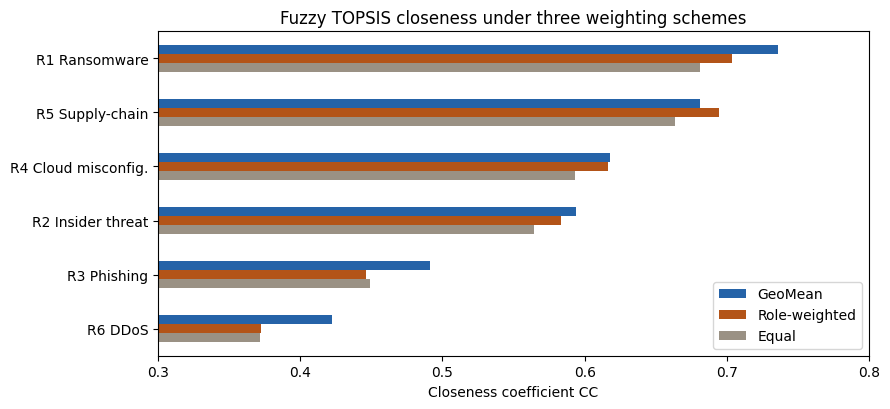

In [10]:
ax = table.drop(columns="Rank").plot.barh(figsize=(9, 4.2), color=["#2563A8", "#B35418", "#9A9184"])
ax.invert_yaxis(); ax.set_xlabel("Closeness coefficient CC"); ax.set_xlim(0.3, 0.8)
ax.set_title("Fuzzy TOPSIS closeness under three weighting schemes"); plt.tight_layout()
plt.savefig("figures/topsis_cc.png", dpi=150)

## Monte Carlo robustness · 10,000 Dirichlet draws (α = 40)

In [11]:
%%time
mc = {}
for label, w in [("GeoMean", w_gm), ("Role-weighted", w_rw)]:
    top, _ = L.monte_carlo(ratings, w, runs=10_000, alpha=40, seed=42)
    mc[label] = np.bincount(top, minlength=6) / len(top) * 100
pd.DataFrame(mc, index=L.ALTS).round(2).rename(columns=lambda c: c + " P(rank 1) %")

CPU times: user 4.72 s, sys: 16.5 ms, total: 4.74 s
Wall time: 6.75 s


,GeoMean P(rank 1) %,Role-weighted P(rank 1) %
R1 Ransomware,87.37,57.87
R2 Insider threat,0.00,0.00
R3 Phishing,0.00,0.00
R4 Cloud misconfig.,0.00,0.01
R5 Supply-chain,12.63,42.12
R6 DDoS,0.00,0.00


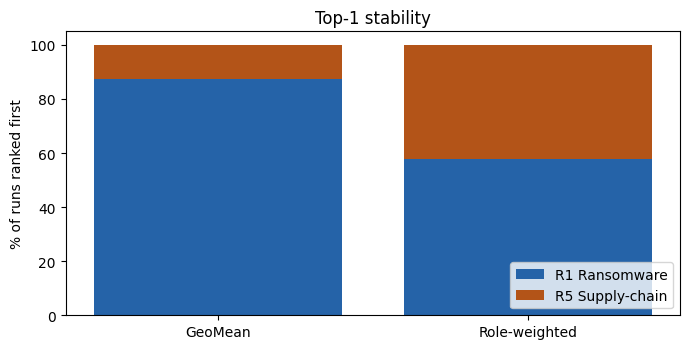

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(["GeoMean", "Role-weighted"], [mc["GeoMean"][0], mc["Role-weighted"][0]], color="#2563A8", label="R1 Ransomware")
ax.bar(["GeoMean", "Role-weighted"], [mc["GeoMean"][4], mc["Role-weighted"][4]],
       bottom=[mc["GeoMean"][0], mc["Role-weighted"][0]], color="#B35418", label="R5 Supply-chain")
ax.set_ylabel("% of runs ranked first"); ax.legend(loc="lower right"); ax.set_title("Top-1 stability")
plt.tight_layout(); plt.savefig("figures/mc_top1.png", dpi=150)